# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170049          # <-- your full roll number
NAME = "Manroop Kaur"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:


# Generate the personalized dataset using the existing function
tickets_df, focus_ticket_ids, fingerprint = generate_dataset(ROLL_NO)

rows = []
processed_results = {}

for _, row in tickets_df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    # Run the official preprocessing pipeline
    result = process_ticket(text)
    processed_results[ticket_id] = result

    rows.append({
        "Ticket ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

# Create per-ticket table
preprocessing_table = pd.DataFrame(rows)

# Add TOTAL row
total_row = {
    "Ticket ID": "TOTAL",
    "Sentences": preprocessing_table["Sentences"].sum(),
    "Tokens": preprocessing_table["Tokens"].sum(),
    "Punctuation Tokens": preprocessing_table["Punctuation Tokens"].sum(),
    "Stopwords": preprocessing_table["Stopwords"].sum(),
    "Unique Tokens": preprocessing_table["Unique Tokens"].sum(),
    "Final Tokens": preprocessing_table["Final Tokens"].sum()
}

preprocessing_table = pd.concat(
    [preprocessing_table, pd.DataFrame([total_row])],
    ignore_index=True
)

print("Roll Number:", ROLL_NO)
print("Name:", NAME)
print("Dataset Fingerprint:", fingerprint)
print("Number of Tickets:", len(tickets_df))

display(preprocessing_table)

# Display actual token lists for one selected ticket
selected_id = focus_ticket_ids[0]
selected_result = processed_results[selected_id]

print("\nSelected Ticket:", selected_id)
print("Raw Text:", tickets_df.loc[
    tickets_df["Ticket_ID"] == selected_id, "Ticket_Text"
].iloc[0])

print("\nSentences:", selected_result["sentences"])
print("\nTokens:", selected_result["tokens"])
print("\nPunctuation Tokens:", selected_result["punct"])
print("\nStopwords:", selected_result["stops"])
print("\nFinal Tokens:", selected_result["final"])


Roll Number: 1024170049
Name: Manroop Kaur
Dataset Fingerprint: 0CF5917C
Number of Tickets: 16


,Ticket ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,7,2,1,7,4
1,T02,2,12,2,4,12,6
2,T03,2,13,2,5,12,6
3,T04,2,14,2,3,14,9
4,T05,2,9,2,1,8,6
5,T06,1,7,1,3,7,3
6,T07,2,10,4,3,8,3
7,T08,2,12,2,5,11,5
8,T09,2,17,2,6,16,9
9,T10,2,15,2,5,14,8



Selected Ticket: T11
Raw Text: Error code 0x80070005 appears.

Sentences: ['Error code 0x80070005 appears.']

Tokens: ['error', 'code', '0x80070005', 'appears', '.']

Punctuation Tokens: ['.']

Stopwords: []

Final Tokens: ['error', 'code', '0x80070005', 'appears']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In my dataset, tokens such as n't, 's, and ca may appear as final tokens. They originate from contractions such as isn't, it's, and can't.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]




patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s<>.,;!?]+|www\.[^\s<>.,;!?]+"

phone_pattern = (
    r"(?<!\w)(?:\+91[-\s]?)?"
    r"(?:\d{5}[-\s]\d{5}|\d{10}|\d{4}[-\s]\d{3}[-\s]\d{4})"
    r"(?!\w)"
)

def analyze_text(text):
    result = {"Raw Text": text}

    for label, pattern in patterns.items():
        result[label] = re.findall(pattern, text)

    cleaned = re.sub(email_pattern, "<EMAIL>", text)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)

    result["After Replacement"] = cleaned
    return result

# Analyze all generated tickets
ticket_results = []

for _, row in tickets_df.iterrows():
    result = analyze_text(row["Ticket_Text"])
    result["Ticket ID"] = row["Ticket_ID"]
    ticket_results.append(result)

display(pd.DataFrame(ticket_results))

# Test the TEST_LINES already defined above
test_results = []

for i, line in enumerate(TEST_LINES, start=1):
    result = analyze_text(line)
    result["Test Line"] = i
    test_results.append(result)

display(pd.DataFrame(test_results))


,Raw Text,Words longer than 5 letters,Numbers,Capitalized words,Words starting with a vowel,After Replacement,Ticket ID
0,Ticket #4521 is still open.,[Ticket],[4521],[Ticket],"[is, open]",Ticket #4521 is still open.,T01
1,Matlab keeps disconnecting during the lab. Is ...,"[Matlab, disconnecting, during, another, solut...",[],"[Matlab, Is]","[Is, another]",Matlab keeps disconnecting during the lab. Is ...,T02
2,Python failed to open while uploading the file...,"[Python, failed, uploading, urgent]",[],"[Python, This]","[open, uploading, is, urgent]",Python failed to open while uploading the file...,T03
3,Student portal failed to open since yesterday....,"[Student, portal, failed, yesterday, several]",[],"[Student, I]","[open, I]",Student portal failed to open since yesterday....,T04
4,The student portal stopped responding. Please ...,"[student, portal, stopped, responding, Please]",[],"[The, Please]",[],The student portal stopped responding. Please ...,T05
5,Why isn't the portal opening?,"[portal, opening]",[],[Why],"[isn, opening]",Why isn't the portal opening?,T06
6,I tried again... still no response!!!,[response],[],[I],"[I, again]",I tried again... still no response!!!,T07
7,LMS was working yesterday during the lab. This...,"[working, yesterday, during, urgent]",[],"[LMS, This]","[is, urgent]",LMS was working yesterday during the lab. This...,T08
8,Lms is showing an error when I use mobile hots...,"[showing, mobile, hotspot, another, computer]",[],"[Lms, I, It]","[is, an, error, I, use, It, on, another]",Lms is showing an error when I use mobile hots...,T09
9,Password keeps asking for login during the lab...,"[Password, asking, during, another, computer]",[],"[Password, It]","[asking, It, on, another]",Password keeps asking for login during the lab...,T10


,Raw Text,Words longer than 5 letters,Numbers,Capitalized words,Words starting with a vowel,After Replacement,Test Line
0,Mail it.helpdesk@thapar.edu or a.b-c@dept.univ...,"[helpdesk, thapar, thapar, thapar]",[],[Mail],"[it, edu, or, a, univ, ac, in, edu, or, edu, it]",Mail <EMAIL> or <EMAIL>; visit <URL>.thapar.ed...,1
1,"Call +91 98765 43210, +91-98765-43210 or 0175-...",[Version],"[91, 98765, 43210, 91, 98765, 43210, 0175, 239...","[Call, Version, Rs]","[or, is]","Call <PHONE>, <PHONE> or <PHONE>. Version 2.0....",2
2,The state-of-the-art lab isn't open; log-in at...,[],[5.30],[The],"[of, art, isn, open, in, at]",The state-of-the-art lab isn't open; log-in at...,3


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Approximately 27 capitalized-word occurrences in my generated tickets and TEST_LINES are capitalized only because they appear at the beginning of a sentence, such as “The”, “I”, “Please”, and “This”. The remaining capitalized words include proper nouns and technical terms such as “Python”, “MATLAB”, and “LMS”.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:


from nltk.tokenize import RegexpTokenizer

pattern = (
    r"https?://[^\s<>]+?[^\s<>.,;!?]|www\.[^\s<>]+?[^\s<>.,;!?]"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|(?<!\w)(?:\+91[-\s]?)?(?:\d{5}[-\s]\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4}|\d{10})(?!\w)"
    r"|\d+(?:\.\d+)+(?!\w)"
    r"|[A-Za-z]+(?:['’][A-Za-z]+)+"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+"
    r"|\d+"
    r"|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Compare the tokenizers on TEST_LINES
print("===== TEST_LINES COMPARISON =====")

for i, line in enumerate(TEST_LINES, start=1):
    custom = my_tokenize(line)
    standard = word_tokenize(line)

    print(f"\nTest Line {i}: {line}")
    print("my_tokenize:", custom)
    print("word_tokenize:", standard)
    print("Different:", custom != standard)

# Compare the tokenizers on all generated tickets
different_tickets = []

for _, row in tickets_df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    if custom != standard:
        different_tickets.append(row["Ticket_ID"])

print("\n===== OBSERVATION =====")
print("Total tickets:", len(tickets_df))
print("Tickets tokenized differently:", len(different_tickets))
print("Ticket IDs:", different_tickets)


===== TEST_LINES COMPARISON =====

Test Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lm', 's', '.', 'thapar', '.', 'edu', '/', 'help', 'or', 'www.th', 'apar', '.', 'edu', '/', 'it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Different: True

Test Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Out of 16 tickets, 3 tickets (T06, T07, and T11) are tokenized differently by my_tokenize() and word_tokenize(). The differences occur because the custom tokenizer preserves contractions, hyphenated words, decimals, versions, emails, URLs, and phone numbers as single tokens, whereas word_tokenize() may split them into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:



from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# Collect unique final tokens from the existing Q1 results
unique_final_tokens = sorted(set(
    token.lower()
    for result in processed_results.values()
    for token in result["final"]
    if token.isalpha()
))

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# Choose a suffix after inspecting the actual dataset words
suffix_candidates = ["ing", "ed", "ly", "es", "s"]
suffix = next(
    (s for s in suffix_candidates
     if sum(w.endswith(s) and len(w) > len(s) + 2
            for w in unique_final_tokens) >= 2),
    None
)

print("Selected suffix:", suffix)
print("Words ending in selected suffix:", [
    w for w in unique_final_tokens
    if suffix and w.endswith(suffix) and len(w) > len(suffix) + 2
])

regexp_stemmer = (
    RegexpStemmer(suffix + "$", min=4) if suffix else None
)

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

tagged_words = nltk.pos_tag(unique_final_tokens)

comparison_rows = []

for word, pos in tagged_words:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word) if regexp_stemmer else word
    lemma = lemmatizer.lemmatize(word, penn_to_wordnet(pos))

    if len({p, l, r, lemma}) > 1:
        comparison_rows.append({
            "Word": word,
            "Porter Stem": p,
            "Lancaster Stem": l,
            "Regexp Stem": r,
            "POS Tag": pos,
            "WordNet Lemma": lemma
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


Selected suffix: ing
Words ending in selected suffix: ['asking', 'disconnecting', 'opening', 'responding', 'running', 'showing', 'uploading', 'working']


,Word,Porter Stem,Lancaster Stem,Regexp Stem,POS Tag,WordNet Lemma
0,another,anoth,anoth,another,DT,another
1,appears,appear,appear,appears,VBZ,appear
2,code,code,cod,code,NN,code
3,computer,comput,comput,computer,NN,computer
4,crashes,crash,crash,crashes,NNS,crash
5,error,error,er,error,NN,error
6,failed,fail,fail,failed,VBD,fail
7,file,file,fil,file,NN,file
8,keeps,keep,keep,keeps,VBZ,keep
9,latest,latest,latest,latest,JJS,late


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming occurs when a stemmer removes too much of a word, potentially making unrelated words share the same stem. Under-stemming occurs when related words are not reduced to a common stem. Examples should be selected from the generated comparison table by examining the actual outputs of PorterStemmer, LancasterStemmer, RegexpStemmer, and WordNetLemmatizer.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,184,86,0.4674
1,S2,152,81,0.5329
2,S3,91,58,0.6374
3,S4,91,56,0.6154



Top 10 words in S1:


,Word,Frequency
0,.,23
1,the,11
2,is,10
3,i,5
4,this,4
5,!,4
6,it,4
7,open,3
8,during,3
9,lab,3



Top 10 words in S3:


,Word,Frequency
0,open,3
1,lab,3
2,another,3
3,urgent,3
4,portal,3
5,please,3
6,error,3
7,still,2
8,matlab,2
9,keeps,2


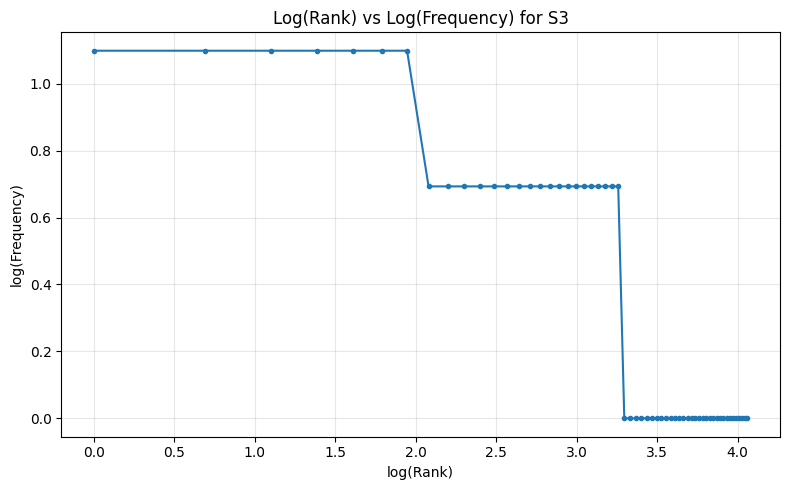


Top 5 bigrams in S1:


,Bigram,Frequency
0,during the,3
1,the lab,3
2,lab .,3
3,. this,3
4,this is,3



Top 5 bigrams in S3:


,Bigram,Frequency
0,failed open,2
1,student portal,2
2,showing error,2
3,use mobile,2
4,mobile hotspot,2


In [9]:



from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt

# S1: all tokens
S1 = [
    token
    for result in processed_results.values()
    for token in result["tokens"]
]

# S2: tokens without punctuation
S2 = [
    token
    for result in processed_results.values()
    for token in result["tokens"]
    if not all(ch in string.punctuation for ch in token)
]

# S3: final tokens
S3 = [
    token
    for result in processed_results.values()
    for token in result["final"]
]

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token.lower()) for token in S3]

# 1. Corpus statistics
corpora = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}

stats = []

for name, tokens in corpora.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

# 2. Top 10 words in S1 and S3
for name, tokens in [("S1", S1), ("S3", S3)]:
    print(f"\nTop 10 words in {name}:")
    display(pd.DataFrame(
        Counter(tokens).most_common(10),
        columns=["Word", "Frequency"]
    ))

# 3. Log(rank) vs log(frequency) for S3
frequency_counts = Counter(S3).most_common()

ranks = list(range(1, len(frequency_counts) + 1))
frequencies = [count for word, count in frequency_counts]

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker="o",
    markersize=3
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Top 5 bigrams in S1 and S3
for name, tokens in [("S1", S1), ("S3", S3)]:
    print(f"\nTop 5 bigrams in {name}:")
    display(pd.DataFrame(
        [
            (" ".join(pair), count)
            for pair, count in Counter(bigrams(tokens)).most_common(5)
        ],
        columns=["Bigram", "Frequency"]
    ))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (Type-Token Ratio) changes from S1 to S4 because preprocessing removes punctuation and stopwords, reducing the total number of tokens, while Porter stemming converts related word forms into common stems, potentially reducing the number of unique tokens. Since TTR is the ratio of unique tokens to total tokens, these changes affect its value. The exact change depends on the words present in my dataset.